# KAN-20, KAN-21 e KAN-22 — Probabilidade e Distribuições: aderência empírica

| | |
|---|---|
| **Projeto** | Análise Estatística — Spaceship Titanic (Pós-Graduação em Deep Learning — CIn/UFPE) |
| **Seção T3** | 3. Probabilidade e Distribuições |
| **Tickets** | [KAN-20](https://megamatic.atlassian.net/browse/KAN-20) distribuições de idade e despesas · [KAN-21](https://megamatic.atlassian.net/browse/KAN-21) QQ-plots · [KAN-22](https://megamatic.atlassian.net/browse/KAN-22) implicações para os testes |
| **Responsável** | Gustavo Menezes Gonçalves |
| **Revisora** | Daniela Amaro |
| **Base de dados** | `data/processed/spaceship_titanic_clean.csv` — 8.693 passageiros × 22 colunas, 0 valores ausentes |
| **Fichamento teórico** | [`05_kan19_variaveis_aleatorias_distribuicoes.ipynb`](05_kan19_variaveis_aleatorias_distribuicoes.ipynb) (KAN-19) |
| **Entrega** | QQ-plots, testes formais de aderência e a tabela de decisão que sustenta os testes da Seção 4 |

> **Aviso de leitura.** Todos os resultados são **descritivos e observacionais**. Aderência a uma distribuição teórica não implica mecanismo gerador; indica apenas que o modelo é uma aproximação útil para resumir e testar os dados.
>
> **Divisão de trabalho com a KAN-19.** O fichamento da KAN-19 já produziu os histogramas, os ajustes Normal e Log-Normal e a separação entre "quem gasta" e "quanto gasta". Este notebook **não repete** essas figuras: ele testa formalmente a aderência, mede o tamanho do desvio e traduz o resultado na escolha dos testes inferenciais. As evidências da KAN-19 são citadas por referência de célula.

## 1. Preparação reproduzível

Uma única célula de configuração concentra imports, semente e leitura da base. Não há etapa de limpeza: a base `spaceship_titanic_clean.csv` já passou pelo pipeline da Seção 1 e é lida por **caminho relativo à raiz do projeto**. A semente fica fixa em 42 para que qualquer reamostragem futura seja reproduzível.

In [1]:
# =============================================================================
# KAN-20/21/22 — Configuração do ambiente
#
# Regras de reprodutibilidade do projeto:
#   - semente fixa em 42;
#   - base lida por caminho relativo (notebook aberto em notebooks/ ou na raiz);
#   - nenhuma etapa de limpeza repetida;
#   - nenhuma figura gravada em disco: os QQ-plots são exibidos inline.
# =============================================================================
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import scipy
import statsmodels
from scipy import stats
from statsmodels.stats.diagnostic import lilliefors
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(42)  # semente fixa do projeto, declarada literalmente

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")

# --- Localização resiliente da base tratada ---------------------------------
CANDIDATOS = [
    Path("../data/processed/spaceship_titanic_clean.csv"),
    Path("data/processed/spaceship_titanic_clean.csv"),
]
DATA_PATH = next((caminho for caminho in CANDIDATOS if caminho.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Base tratada não encontrada a partir de notebooks/ ou da raiz.")

RAIZ = DATA_PATH.parent.parent
df = pd.read_csv(DATA_PATH)

print(f"Base: {df.shape[0]:,} passageiros x {df.shape[1]} colunas".replace(",", "."))
print(f"Valores ausentes: {int(df.isna().sum().sum())}")
print(f"Semente: {SEED}")
print(f"Dependências: scipy {scipy.__version__} | statsmodels {statsmodels.__version__}")

Base: 8.693 passageiros x 22 colunas
Valores ausentes: 0
Semente: 42
Dependências: scipy 1.18.1 | statsmodels 0.15.0


**Leitura.** A base tem **8.693 passageiros × 22 colunas e zero valores ausentes**, então não há imputação a refazer. As bibliotecas usadas já fazem parte do ambiente do projeto (`scipy` 1.18.1 e `statsmodels` 0.15.0); a versão importa porque o teste de Lilliefors mudou de comportamento e passou a aceitar o método `approx`, usado na Seção 5.

## 2. O que a KAN-19 já estabeleceu e o que este notebook acrescenta

O fichamento da KAN-19 não é apenas teórico: ele já produziu evidência empírica sobre a forma das distribuições. A tabela abaixo localiza essa evidência para que ela seja **citada**, e não refeita.

| Evidência | Onde está | Conclusão já registrada |
|---|---|---|
| Idade observada × Normal ajustada ($\mu = 28{,}8$; $\sigma = 14{,}4$) | KAN-19, célula 14 (`fig_07`) | A curva acompanha o centro e subestima as caudas; há concentração em idade 0 |
| "Quem gasta" × "quanto gasta"; Log-Normal nos positivos ($\ln$: $\mu = 7{,}33$; $\sigma = 0{,}96$) | KAN-19, célula 17 (`fig_08`) | 41,9% com gasto zero; nos positivos o formato é de sino, mas há mistura de populações |
| Implicações preliminares para a KAN-20 a KAN-22 | KAN-19, célula 22 | A escolha dos testes deve considerar zeros e caudas |

**O que falta e este notebook entrega:** (i) definir explicitamente a **população** de cada teste — o erro clássico é testar `TotalSpend` completo, que é uma mistura com 41,92% de zeros, contra uma lei contínua; (ii) quantificar a forma com QQ-plots; (iii) aplicar testes formais com **tamanho de efeito**; (iv) traduzir o resultado na tabela de decisão da KAN-22, reconciliada com o que a Seção 4 efetivamente executou.

## 3. KAN-20 — Populações de análise e momentos

Antes de qualquer teste, é preciso declarar **qual população** está sendo testada. `TotalSpend` não é uma variável contínua: é uma mistura *hurdle*, com uma decisão binária ("gastou ou não") e, condicionada a gastar, um valor positivo. Testar a variável completa contra uma Normal mede a mistura, não a forma dos gastos.

As populações adotadas são:

- **`Age` (todos):** 8.693 passageiros, incluindo os 178 com idade 0 (bebês);
- **`Age > 0`:** 8.515 passageiros, usada apenas como sensibilidade na Seção 5;
- **`TotalSpend` (todos):** 8.693 passageiros, com 3.644 zeros — retrato da mistura;
- **`log1p(TotalSpend) | TotalSpend > 0`:** 5.049 passageiros que gastaram;
- **gastos por serviço | valor > 0:** entre 2.973 e 3.281 passageiros por rubrica.

A célula seguinte calcula, para cada população, tamanho, proporção de zeros, média, desvio, assimetria e curtose. A assimetria mede o puxão da cauda (0 = simétrica); a curtose em excesso mede o peso das caudas (0 = Normal).

In [2]:
# =============================================================================
# KAN-20 — Populações e momentos
#
# A mesma variável pode ter formas diferentes conforme a população:
#   - TotalSpend completo é uma mistura (hurdle) com 41,92% de zeros;
#   - log1p(TotalSpend) nos positivos isola a forma dos gastos efetivos;
#   - cada serviço tem 62% a 66% de zeros e é tratado apenas nos positivos.
# =============================================================================
SERVICOS = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

populacoes = {
    "Age (todos)": df["Age"],
    "Age > 0": df.loc[df["Age"] > 0, "Age"],
    "TotalSpend (todos)": df["TotalSpend"],
    "log1p(TotalSpend) | > 0": np.log1p(df.loc[df["TotalSpend"] > 0, "TotalSpend"]),
}
for servico in SERVICOS:
    populacoes[f"{servico} | > 0"] = df.loc[df[servico] > 0, servico]

linhas = []
for nome, serie in populacoes.items():
    linhas.append(
        {
            "População": nome,
            "n": len(serie),
            "Zeros (n)": int((serie == 0).sum()),
            "Zeros (%)": 100 * (serie == 0).mean(),
            "Média": serie.mean(),
            "Desvio": serie.std(ddof=1),
            "Assimetria": stats.skew(serie, bias=False),
            "Curtose (excesso)": stats.kurtosis(serie, bias=False),
        }
    )

momentos = pd.DataFrame(linhas).set_index("População")
momentos

,n,Zeros (n),Zeros (%),Média,Desvio,Assimetria,Curtose (excesso)
População,,,,,,,
Age (todos),8693,178,2.048,28.783,14.353,0.431,0.160
Age > 0,8515,0,0.000,29.384,13.879,0.543,0.198
TotalSpend (todos),8693,3644,41.919,"1,447.462","2,808.280",4.400,27.279
log1p(TotalSpend) | > 0,5049,0,0.000,7.335,0.948,-0.189,4.925
RoomService | > 0,3022,0,0.000,637.388,995.599,4.066,27.911
FoodCourt | > 0,3144,0,0.000,"1,248.096","2,460.113",4.421,28.761
ShoppingMall | > 0,2973,0,0.000,496.931,939.757,8.546,147.119
Spa | > 0,3281,0,0.000,809.278,"1,717.207",4.862,32.822
VRDeck | > 0,3095,0,0.000,840.054,"1,777.241",4.838,32.914


**Leitura dos momentos.**

- **`Age` (todos).** Assimetria **0,43** e curtose **0,16**: desvio moderado à direita, caudas próximas das de uma Normal. A ressalva é a **discretização** — são apenas 80 valores distintos — e o **pico em idade 0** (178 passageiros, 2,05%), que nenhuma densidade contínua representa.
- **`TotalSpend` (todos).** Assimetria **4,40** e curtose **27,28**: a média (US$ 1.447,46) é maior que a mediana (US$ 717,00) e não resume bem a variável. Os 41,92% de zeros são metade da explicação.
- **`log1p(TotalSpend) | > 0`.** A transformação logarítmica praticamente elimina a assimetria (**−0,19**), mas **não** as caudas: a curtose sobe para **4,93**. Ou seja, o log resolve o puxão à direita e revela que os gastos positivos são uma mistura de perfis, com caudas mais pesadas que a Log-Normal.
- **Serviços (positivos).** Assimetria entre **4,07** (`RoomService`) e **8,55** (`ShoppingMall`). Mesmo entre quem gastou, cada rubrica tem cauda longa; a Log-Normal é aproximação de trabalho, não descrição exata.

Esses números antecipam a conclusão da Seção 5: a Normal descreve `Age` de forma grosseira e a Log-Normal descreve os gastos positivos de forma razoável no corpo, mas ambas serão rejeitadas por testes formais.

## 4. KAN-21 — QQ-plots

O **QQ-plot** (quantil-quantil) compara os quantis observados com os quantis teóricos de uma distribuição. Se os pontos caem sobre a reta de 45°, a aderência é boa. Os desvios têm leitura própria:

- pontos **acima** da reta no extremo direito → cauda direita mais longa que a teórica;
- pontos **abaixo** da reta no extremo esquerdo → cauda esquerda mais longa;
- **degraus** horizontais → variável discreta (muitos empates);
- **curvatura em S** → assimetria ou caudas mais pesadas.

Atenção: no `probplot` do SciPy, a média e o desvio são **estimados da própria amostra**. Isso é o correto para um diagnóstico descritivo, mas invalida o Kolmogorov-Smirnov clássico — motivo pelo qual a Seção 5 usa Lilliefors.

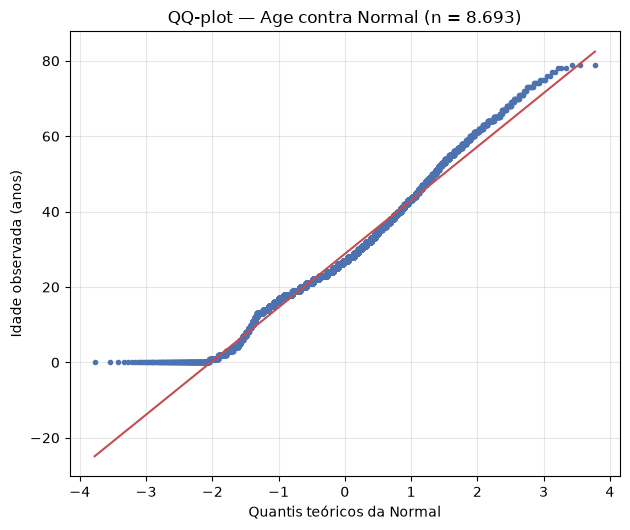

In [3]:
# =============================================================================
# KAN-21 — QQ-plot de Age contra a Normal
#
# A reta representa a Normal com média e desvio estimados da amostra.
# Desvios sistemáticos nos extremos indicam caudas diferentes da Normal.
# =============================================================================
fig, ax = plt.subplots(figsize=(6.4, 5.4))
stats.probplot(df["Age"], dist="norm", plot=ax, fit=True)
ax.get_lines()[0].set_markerfacecolor("#4C72B0")
ax.get_lines()[0].set_markeredgecolor("#4C72B0")
ax.get_lines()[0].set_markersize(3)
ax.get_lines()[1].set_color("#C44E52")
ax.set_title("QQ-plot — Age contra Normal (n = 8.693)")
ax.set_xlabel("Quantis teóricos da Normal")
ax.set_ylabel("Idade observada (anos)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Leitura do QQ-plot de `Age`.** Na faixa central (quantis teóricos entre −1 e 1), **4.685 dos 5.935 pontos ficam abaixo da reta** — e não acima. A mediana observada (27 anos) é menor que a prevista pelo ajuste (28,8 anos): o miolo da distribuição real está em idades mais baixas do que a Normal desloca. Três trechos explicam o desenho:

- no extremo **esquerdo**, um patamar horizontal na altura de 0 anos marca o pico discreto de 178 bebês, que nenhuma densidade contínua representa, e mantém os pontos **acima** da reta;
- na metade **superior** do miolo (entre 0 e 1), 2.758 de 2.968 pontos ficam **abaixo**: entre 20 e 40 anos estão 55,3% dos passageiros, contra 51,3% previstos pela Normal;
- **acima de 1**, os pontos voltam a ficar **acima** da reta (1.353 de 1.379), de modo que o desenho fecha em S.

Os degraus ao longo da reta vêm da discretização (80 valores inteiros). O padrão combina **átomo em 0, discretização e concentração entre 20 e 40 anos** — não é de cauda pesada, como confirmam a curtose 0,16 e o W de 0,980. É o que explica o D de 0,076: a Normal serve para resumir o centro, mas não para prometer aderência exata.

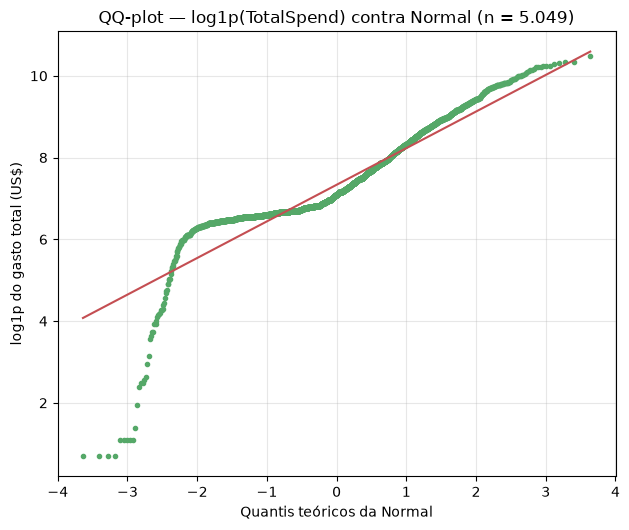

In [4]:
# =============================================================================
# KAN-21 — QQ-plot de log1p(TotalSpend) contra a Normal
#
# População: apenas os 5.049 passageiros com TotalSpend > 0.
# Os 3.644 zeros são uma decisão binária e não pertencem a esta população.
# =============================================================================
gasto_positivo = df.loc[df["TotalSpend"] > 0, "TotalSpend"]
log_gasto = np.log1p(gasto_positivo)

fig, ax = plt.subplots(figsize=(6.4, 5.4))
stats.probplot(log_gasto, dist="norm", plot=ax, fit=True)
ax.get_lines()[0].set_markerfacecolor("#55A868")
ax.get_lines()[0].set_markeredgecolor("#55A868")
ax.get_lines()[0].set_markersize(3)
ax.get_lines()[1].set_color("#C44E52")
ax.set_title("QQ-plot — log1p(TotalSpend) contra Normal (n = 5.049)")
ax.set_xlabel("Quantis teóricos da Normal")
ax.set_ylabel("log1p do gasto total (US$)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Leitura do QQ-plot de `log1p(TotalSpend)`.** O desvio mais forte está à **esquerda**: abaixo de aproximadamente −2,3, os pontos despencam quase na vertical, de 4 para 0,7. Isso corresponde a gastos positivos mínimos (US$ 1 a US$ 30), muito mais numerosos do que a Log-Normal prevê. No **corpo** (quantis teóricos entre −1,5 e 0,5), os pontos ficam levemente abaixo da reta. No **trecho superior** (entre 0,5 e 2,5), ficam acima: há excesso de gastos altos. No extremo direito, voltam à reta.

Esse formato em S, com uma perna vertical à esquerda, é a assinatura da curtose **4,93** medida na Seção 3. A leitura de negócio é direta: a maioria dos passageiros que gasta tem consumo intermediário parecido, mas existem tanto micropassageiros quanto um grupo pequeno de gastos muito altos. Uma única Log-Normal não cobre as duas pontas.

## 5. Testes formais de aderência

As hipóteses, para cada variável, são:

- $H_0$: a variável segue uma distribuição Normal (para `Age`) ou uma Normal na escala $\log1p$ (para os gastos positivos);
- $H_1$: a variável não segue essa distribuição;
- nível de significância $\alpha = 0,05$.

Dois testes são aplicados em paralelo, por motivos diferentes:

1. **Shapiro-Wilk** — teste de aderência com boa potência em amostras pequenas e médias. Com $n > 5.000$ o $p$-valor deixa de ser confiável: o próprio SciPy emite aviso. O **W** continua informativo (1 = aderência perfeita).
2. **Kolmogorov-Smirnov com correção de Lilliefors** — o KS clássico exige parâmetros conhecidos; quando a média e o desvio são estimados da amostra, o $p$ do KS fica **conservador** (rejeita de menos). Lilliefors corrige isso. Reporta-se **D**, a maior distância entre a distribuição empírica e a teórica (0 = aderência perfeita).

Com $n$ na casa dos milhares, qualquer desvio mínimo é significativo. Por isso a decisão deste notebook **não** se apoia no $p$-valor: ela se apoia no **tamanho do desvio** (W e D) e na leitura do QQ-plot.

In [5]:
# =============================================================================
# Testes formais de aderência
#
# Shapiro-Wilk  : reporta W (1 = aderência perfeita); p instável para n > 5.000.
# Lilliefors    : KS com parâmetros estimados; pvalmethod="approx" evita o
#                 piso de 0,001 que o método padrão devolve em amostras grandes.
# =============================================================================
def fmt_p(valor: float) -> str:
    """Formata p-valores em notação científica com vírgula decimal."""
    if valor < 1e-300:
        return "< 1e-300"
    return f"{valor:.2e}".replace(".", ",")


alvos = {
    "Age (todos)": df["Age"],
    "Age > 0": df.loc[df["Age"] > 0, "Age"],
    "log1p(TotalSpend) | > 0": log_gasto,
}

with warnings.catch_warnings(record=True) as capturados:
    warnings.simplefilter("always")
    registros = []
    for nome, serie in alvos.items():
        w_shapiro, p_shapiro = stats.shapiro(serie)
        d_lilliefors, p_lilliefors = lilliefors(serie, dist="norm", pvalmethod="approx")
        registros.append(
            {
                "População": nome,
                "n": len(serie),
                "W (Shapiro)": w_shapiro,
                "p (Shapiro)": p_shapiro,
                "D (Lilliefors)": d_lilliefors,
                "p (Lilliefors)": p_lilliefors,
            }
        )

aderencia = pd.DataFrame(registros).set_index("População")
aderencia["Decisão (α = 0,05)"] = np.where(
    aderencia["p (Lilliefors)"] < 0.05, "Rejeita H0", "Não rejeita H0"
)

avisos = sorted({str(aviso.message) for aviso in capturados})
print(f"Avisos do SciPy durante os testes: {len(avisos)}")
for aviso in avisos:
    print(f"  - {aviso}")

aderencia.assign(**{
    "p (Shapiro)": aderencia["p (Shapiro)"].map(fmt_p),
    "p (Lilliefors)": aderencia["p (Lilliefors)"].map(fmt_p),
})

Avisos do SciPy durante os testes: 3
  - scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5049.
  - scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8515.
  - scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8693.


,n,W (Shapiro),p (Shapiro),D (Lilliefors),p (Lilliefors),"Decisão (α = 0,05)"
População,,,,,,
Age (todos),8693,0.980,"3,46e-33",0.076,"2,50e-136",Rejeita H0
Age > 0,8515,0.975,"8,11e-36",0.085,"1,45e-166",Rejeita H0
log1p(TotalSpend) | > 0,5049,0.891,"8,57e-51",0.126,"1,14e-222",Rejeita H0


**Leitura da tabela.** As três populações **rejeitam** $H_0$, como era esperado com $n$ de 5 mil a 8,7 mil. O que importa é a magnitude:

| População | W | D | Leitura |
|---|---:|---:|---|
| `Age` (todos) | 0,980 | 0,076 | Desvio **pequeno**. A Normal é aproximação de trabalho aceitável para o centro; a rejeição vem da discretização e da concentração central, não de cauda pesada. |
| `Age > 0` | 0,975 | 0,085 | Desvio **maior** ao retirar os zeros (ver Seção 5.1). |
| `log1p(TotalSpend)` | 0,891 | 0,126 | Desvio **moderado a grande**. A Log-Normal descreve o corpo, mas não as duas caudas. |

O aviso do SciPy sobre o $p$ do Shapiro aparece porque duas populações passam de 5.000 observações. Nenhuma decisão deste notebook depende desse $p$: a estatística descritiva (W e D) e o QQ-plot são suficientes, e o Lilliefors com `approx` confirma a rejeição sem depender do piso de 0,001.

### 5.1 Sensibilidade: retirar o pico em `Age = 0`

A hipótese natural é que o pico de 178 bebês em idade 0 seja o responsável pela rejeição da Normal. A linha `Age > 0` da tabela testa exatamente isso — e o resultado **contraria** a hipótese:

- **W cai** de 0,980 para 0,975;
- **D sobe** de 0,076 para 0,085;
- a assimetria **aumenta** de 0,43 para 0,54.

Ou seja, retirar os zeros **piora** a aderência. A explicação é que o pico em 0 ocupa uma região em que a Normal ajustada ainda tem densidade; ao removê-lo, sobra uma distribuição mais assimétrica e igualmente discreta. A rejeição, portanto, **não** é causada pelos bebês: é causada pela **discretização** (80 valores inteiros) e pela **concentração no centro**, que a Normal não reproduz: a curva teórica espalha massa pelos extremos que os dados não têm.

Consequência prática: não se deve "corrigir" a distribuição removendo crianças do recorte. O tratamento correto é declarar a limitação e preferir testes não paramétricos quando o grupo comparado for pequeno.

## 6. KAN-22 — Implicações para os testes inferenciais

A tabela abaixo converte a evidência das Seções 3 a 5 em escolha de teste. A coluna "o que a Seção 4 usou" foi conferida contra `docs/conclusoes/04_testes_hipoteses_anova.md`, para que a recomendação não seja teórica e desconectada do que foi executado.

| Variável | Modelo de referência | O que a Seção 4 usou | Por quê |
|---|---|---|---|
| `Age` | Normal aproximada (D = 0,076) | Não testada por grupo; entra como preditora contínua na Seção 5 | Assimetria moderada e $n$ grande sustentam a média; se houver comparação de grupos pequenos, usar Mann-Whitney como salvaguarda |
| `TotalSpend` (todos) | Mistura *hurdle*: Bernoulli × Log-Normal | Levene → **$t$ de Welch** principal e **Mann-Whitney** complementar | Heterocedasticidade severa e 41,92% de zeros: a média engana, então mediana e teste de postos são obrigatórios |
| `log1p(TotalSpend) | > 0` | Log-Normal (corpo) com caudas pesadas | KAN-31 aplica `log1p` na regressão linear | A transformação corrige a assimetria (−0,19); o erro-padrão HC3 entra pela heterocedasticidade dos resíduos, **não** pela curtose |
| Gastos por serviço | Log-Normal grosseira; assimetria 4,1 a 8,5 | Não testados individualmente | Se algum serviço for comparado, usar Mann-Whitney ou Kruskal-Wallis, nunca $t$ de Student |
| Categóricas (`HomePlanet`, `CryoSleep`, `VIP`) | Bernoulli / multinomial | **Qui-quadrado** de Pearson, com Yates quando $df = 1$ | A normalidade não é pressuposto do qui-quadrado; o pressuposto é frequência esperada ≥ 5, atendido em 100% das células |

**O que muda na prática.**

1. **Média de gasto não é um bom resumo.** Como a distribuição é uma mistura com 41,92% de zeros, o relatório deve apresentar **mediana** e proporção de gasto zero, não só a média.
2. **O teste $t$ de Student clássico está descartado** para gastos: a razão de variâncias entre grupos passa de 37× e a distribuição é fortemente assimétrica. Welch mais Mann-Whitney é a combinação correta.
3. **A regressão linear de `TotalSpend` precisa de `log1p`.** Sem a transformação, os resíduos seriam dominados pela cauda direita; com ela, a assimetria cai para −0,19, mas a curtose 4,93 **permanece** e é declarada como limitação. O HC3 é usado porque os resíduos são heterocedásticos: ele corrige a variância estimada, **não** a forma da distribuição.
4. **A Normal para `Age` é defensável como aproximação**, desde que a limitação seja declarada — mas esse não é o motivo de a idade entrar no modelo. Regressão linear e logística **não exigem preditoras normais**: a aproximação Normal descreve a variável isolada, útil para comparar médias; no modelo, o que importa é a especificação da relação e o comportamento dos resíduos.
5. **A discretização de `Age` não invalida a análise**, mas impede prometer aderência exata. Em grupos pequenos (por exemplo, comparar idades entre decks raros), o teste de postos é mais seguro.

## 7. Síntese

1. **A população do teste importa mais que o teste.** `TotalSpend` completo é uma mistura com 41,92% de zeros; testar a variável inteira contra uma lei contínua mede a mistura, não os gastos.
2. **A Normal descreve `Age` de forma grosseira, com desvio pequeno** (W = 0,980; D = 0,076). O que atrapalha não é o pico em zero — retirá-lo piora a aderência —, mas a discretização e a concentração entre 20 e 40 anos, que o QQ-plot mostra em S: miolo abaixo da reta e pontas acima.
3. **A Log-Normal descreve o corpo dos gastos positivos, mas não as caudas** (W = 0,891; D = 0,126; curtose 4,93). Há micropassageiros e um grupo pequeno de gastos muito altos.
4. **Com $n$ grande, o $p$-valor não decide nada.** Todos os testes rejeitam; a decisão útil vem do tamanho do desvio e da leitura do QQ-plot.
5. **A escolha dos testes da Seção 4 está justificada:** Welch e Mann-Whitney para gastos, qui-quadrado para categóricas e `log1p` com HC3 para heterocedasticidade na regressão. Para o cliente, isso significa relatar **medianas e proporções**, não apenas médias.

In [6]:
# =============================================================================
# Checagem de reprodutibilidade
#
# Guarda-corpo: se a base mudar, estes números deixam de bater e o notebook
# falha em vez de produzir interpretações desatualizadas.
# =============================================================================
assert len(df) == 8693, "A base tratada deve ter 8.693 passageiros."
assert int((df["TotalSpend"] > 0).sum()) == 5049, "Esperados 5.049 passageiros com gasto positivo."
assert int((df["Age"] == 0).sum()) == 178, "Esperados 178 passageiros com idade 0."
assert SEED == 42, "A semente do projeto é 42."
print("Checagens de reprodutibilidade: OK")

Checagens de reprodutibilidade: OK
